# Diabetes 130-US Hospitals

## 1. EDA & problem framing

### Downloading necessary libraries

We start by downloading the necessary libraries to better visualize the data

In [1]:
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

### Dataset loading

Load the data from the sklearn library (Diabetes data)

In [2]:
import pandas as pd

from sklearn.datasets import fetch_openml
# Option 3 -- Diabetes 130 Hospitals
diabetes = fetch_openml(data_id=4541, as_frame=True)
X, y = diabetes.data, diabetes.target

# 1.1 Problem Definition

#### Goal: Predict whether a patient will be readmitted to the hospital
#### The data comes from 130 US hospitals between 1999-2008; each row is one hospital stay of a patient with diabetes. The same patient could have several stays.


# 1.2 Target 

#### Readmitted has 3 labels, <30; >30 and NO.

In [3]:
y.value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

#### Check to see there no missing values in the target

In [4]:
y.isna().sum()

np.int64(0)

#### We convert it to binary values (1, 0) maning yes and no respectively.

In [5]:
y = y.map({'NO': 0, '<30': 1, '>30': 1})

#### Check to make sure it works!

In [6]:
y.value_counts()

readmitted
0    54864
1    46902
Name: count, dtype: int64

# 1.3 Visualize the data

In [7]:
df = pd.DataFrame(X, columns=diabetes.feature_names)

In [8]:
df.shape

(101766, 49)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 49 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   encounter_id              101766 non-null  int64   
 1   patient_nbr               101766 non-null  int64   
 2   race                      101766 non-null  category
 3   gender                    101766 non-null  category
 4   age                       101766 non-null  category
 5   weight                    101766 non-null  category
 6   admission_type_id         101766 non-null  int64   
 7   discharge_disposition_id  101766 non-null  int64   
 8   admission_source_id       101766 non-null  int64   
 9   time_in_hospital          101766 non-null  int64   
 10  payer_code                101766 non-null  category
 11  medical_specialty         101766 non-null  category
 12  num_lab_procedures        101766 non-null  int64   
 13  num_procedures            101766 non-nul

### We see the data inside each row and as we can see we have some data that has question marks, so we need to change them to NaaNs to have a better view

In [10]:
df.head(10)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,examide,citoglipton,insulin,glyburide.metformin,glipizide.metformin,glimepiride.pioglitazone,metformin.rosiglitazone,metformin.pioglitazone,change,diabetesMed
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,No
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,No,Up,No,No,No,No,No,Ch,Yes
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,No,Yes
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,No,Up,No,No,No,No,No,Ch,Yes
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,No,Steady,No,No,No,No,No,Ch,Yes
5,35754,82637451,Caucasian,Male,[50-60),?,2,1,2,3,...,No,No,Steady,No,No,No,No,No,No,Yes
6,55842,84259809,Caucasian,Male,[60-70),?,3,1,2,4,...,No,No,Steady,No,No,No,No,No,Ch,Yes
7,63768,114882984,Caucasian,Male,[70-80),?,1,1,7,5,...,No,No,No,No,No,No,No,No,No,Yes
8,12522,48330783,Caucasian,Female,[80-90),?,2,1,4,13,...,No,No,Steady,No,No,No,No,No,Ch,Yes
9,15738,63555939,Caucasian,Female,[90-100),?,3,3,4,12,...,No,No,Steady,No,No,No,No,No,Ch,Yes


#### We create a list called cols_count that includes the countable features in our dataset. Below we can see the descriptive statistics of said features.

##### Below we can see the stays in the hospitals range between 1 to 14 days.
##### We can see that for each patient, there needs to be AT LEAST 1 lab procedure.

In [11]:
cols_count = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
df[cols_count].describe()

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


# 1.4 Cleaning the Data

##### We do a missingno matrix and immediately see that there are no missing values, which is strange. After reviewing the data, we can see that there are ?'s in these columns (weight, medical specialty, payer_code and race). 
##### We also saw that there is a 'None' value in the A1Cresult and max_glu_serum which means no test was performed.
##### Moreover, the gender column has 3 stays which are were recorded as Unknown/Invalid.
##### We also check for duplicated in our data and see that there are none.

<Axes: >

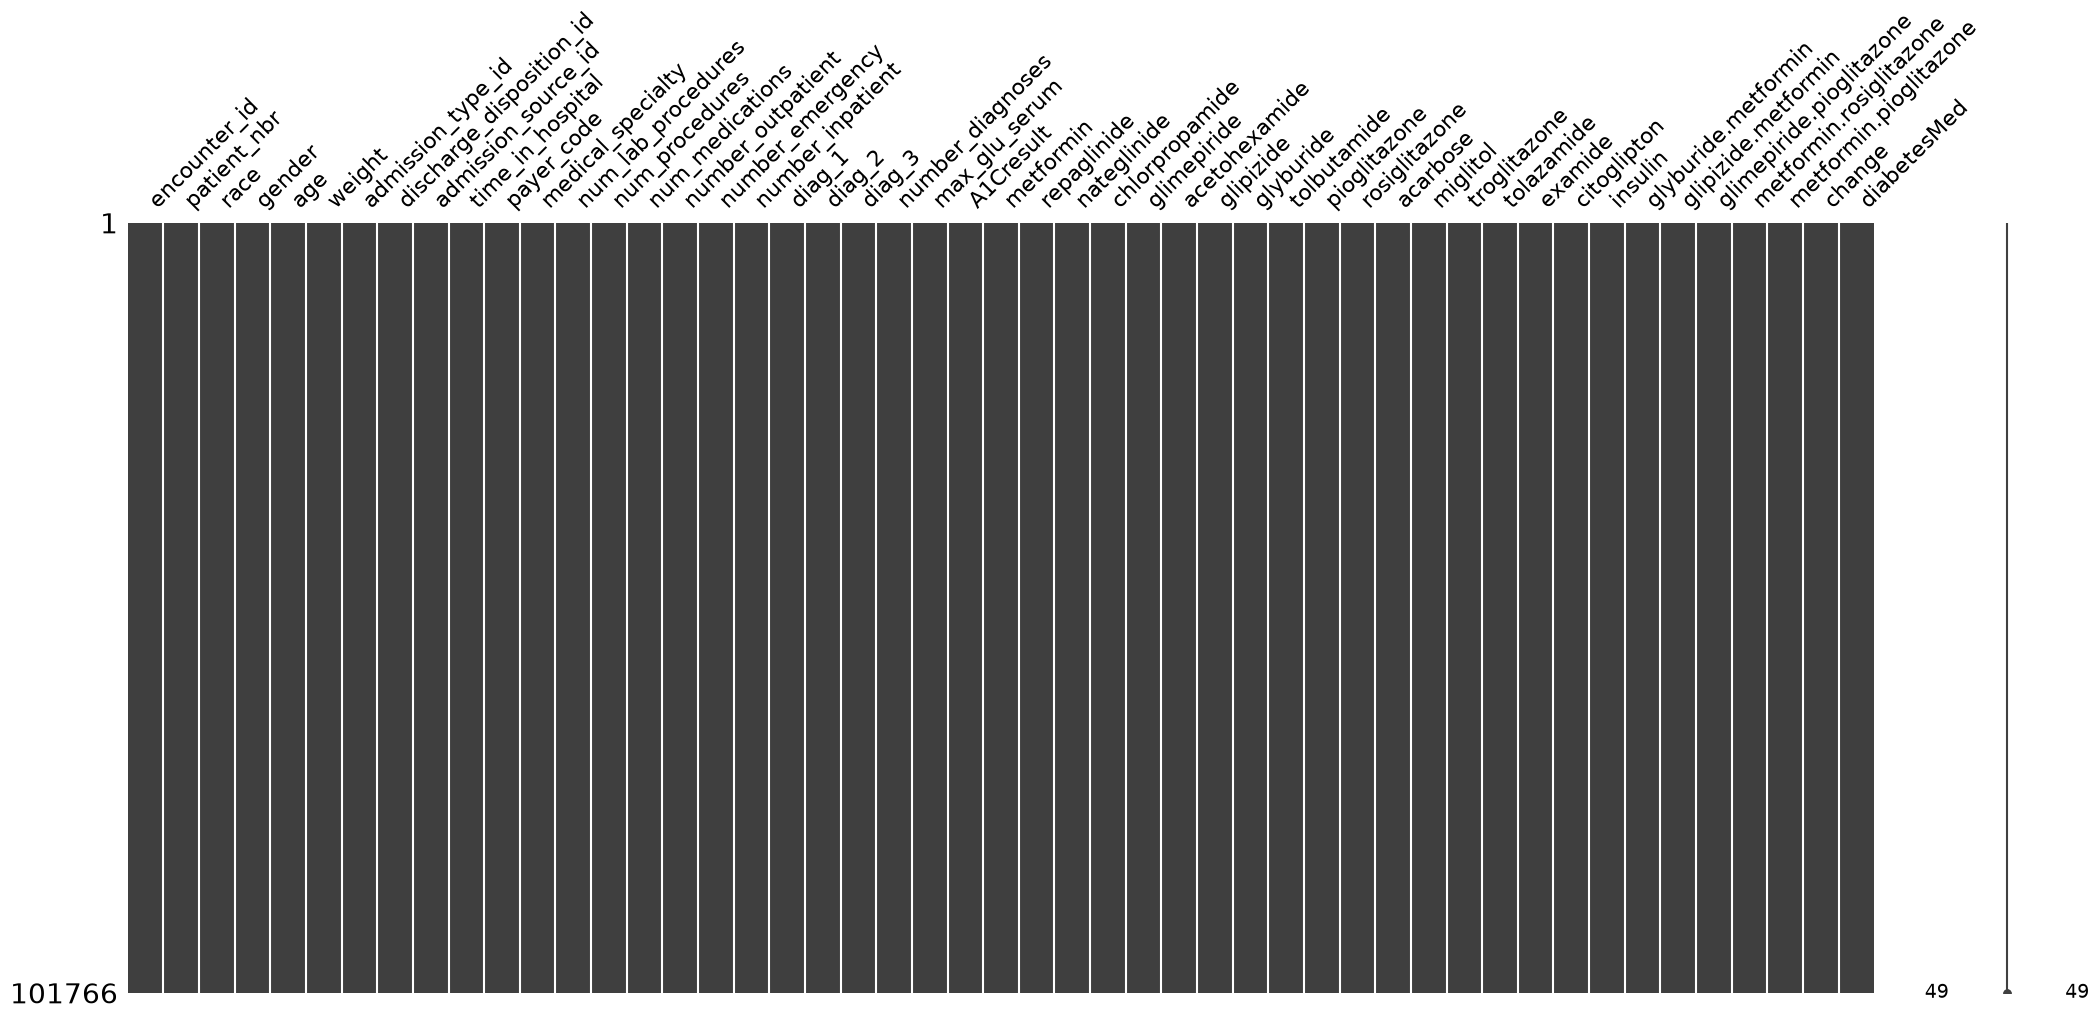

In [12]:
msno.matrix(df)

In [13]:
df.duplicated().sum()

np.int64(0)

##### Now we replace all the missing values with NaaN.

In [14]:
df = df.replace('?', np.nan)
df = df.replace('None', np.nan)
df = df.replace('Unknown/Invalid', np.nan)
df.isna().sum()

encounter_id                    0
patient_nbr                     0
race                         2273
gender                          3
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

##### Now that we established that we have a lot of missing values, we will delete the top 5 columns because even if we fill with the mean, median or mode, the analysis will be flawed.

In [15]:
missing_percentage = df.isna().sum() / len(df) * 100
missing_percentage[missing_percentage > 0].sort_values(ascending=False).round(4)

weight               96.8585
max_glu_serum        94.7468
A1Cresult            83.2773
medical_specialty    49.0822
payer_code           39.5574
race                  2.2336
diag_3                1.3983
diag_2                0.3518
diag_1                0.0206
gender                0.0029
dtype: float64

In [16]:
df = df.drop(columns=['weight', 'max_glu_serum', 'A1Cresult', 'medical_specialty','payer_code'])

##### Now, we replace diagnostic missing values with "Unknown".

In [17]:
for col in ["diag_1", "diag_2", "diag_3"]:
    df[col] = df[col].astype("string").fillna("Unknown")

<Axes: >

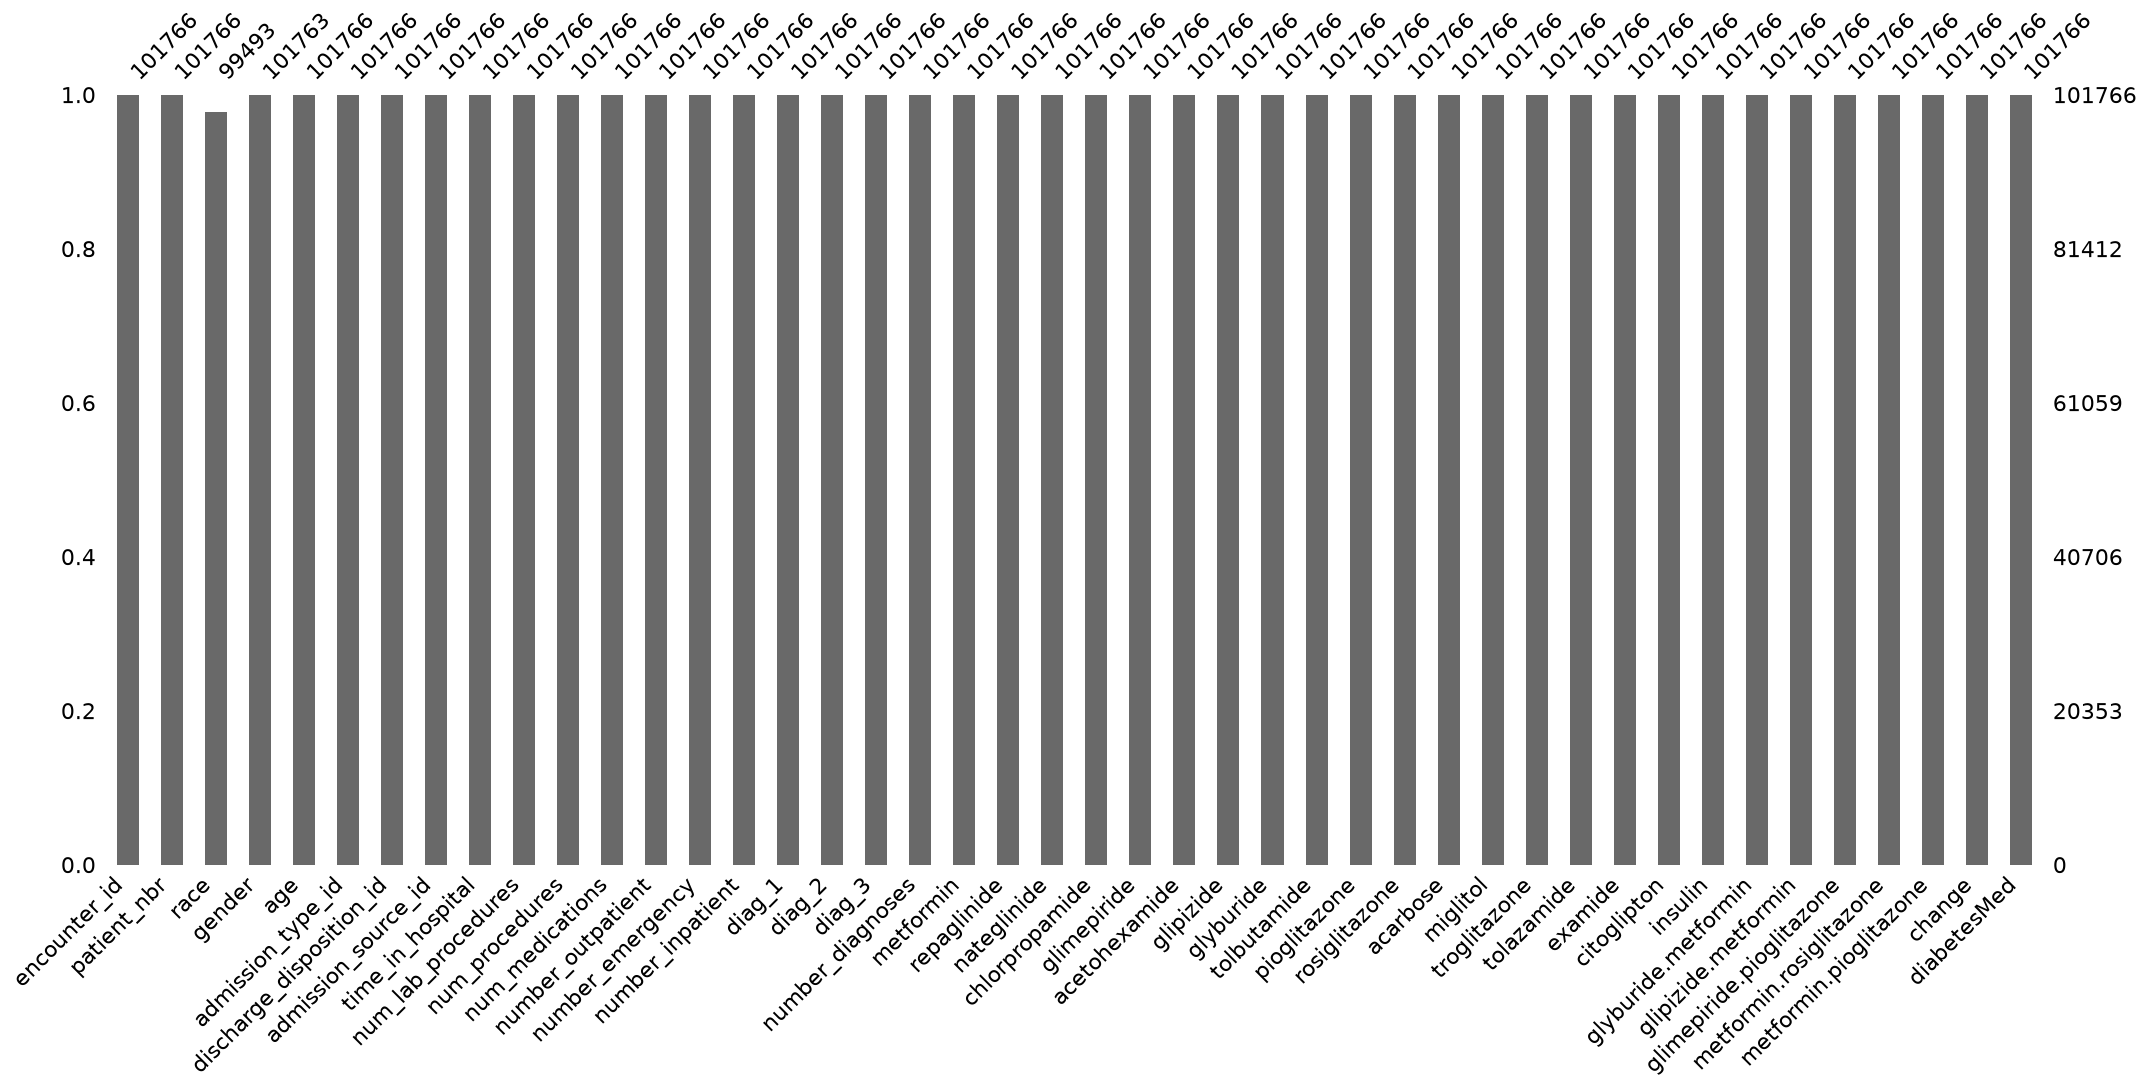

In [18]:
msno.bar(df)

### We run a df.describe on the diagnoses and see which diagnosis is most repititive. 
#### 1. Based on the information below, the main diagnosis is 428 which refers to heart failure :(
#### 2. Then, the second most common diagnosis is 276 which is disorder of fluid :(
#### 3. Finally, the third most common diagnosis is 250 which is Diabetes Mellitus :(

In [19]:
df[["diag_1", "diag_2", "diag_3"]].mode()

,diag_1,diag_2,diag_3
0,428,276,250


# 1.5 Variables Distributions 

##### Visualize the binary target distribution in percentages.

In [20]:
y.value_counts(normalize=True) * 100

readmitted
0    53.911916
1    46.088084
Name: proportion, dtype: float64

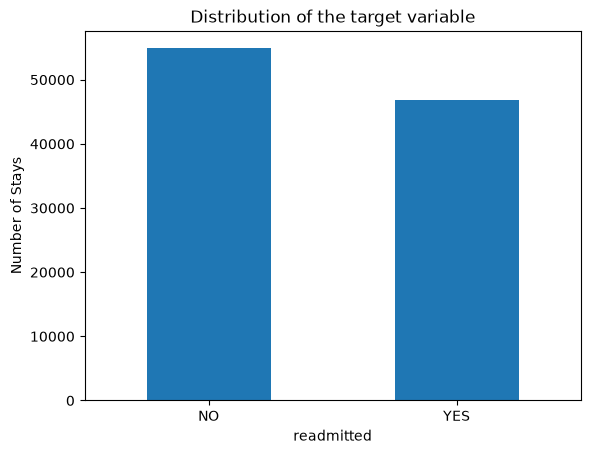

In [21]:
y.value_counts().sort_index().plot.bar()
plt.title("Distribution of the target variable")
plt.xticks([0, 1], ['NO', 'YES'], rotation=0)
plt.ylabel("Number of Stays")
plt.show()

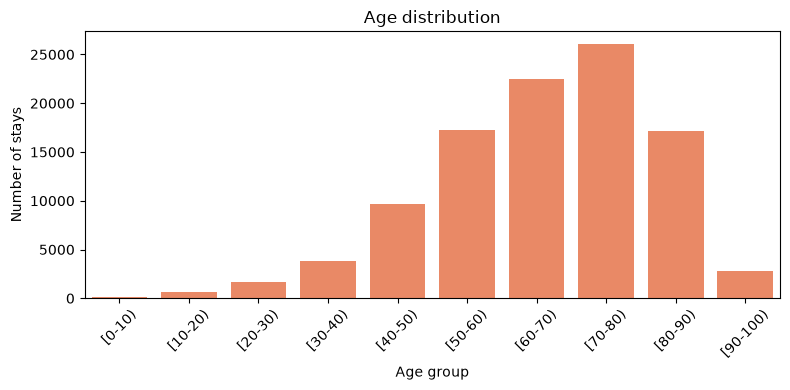

In [22]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="age", order=sorted(df["age"]), color="coral")
plt.title("Age distribution")
plt.xlabel("Age group")
plt.ylabel("Number of stays")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

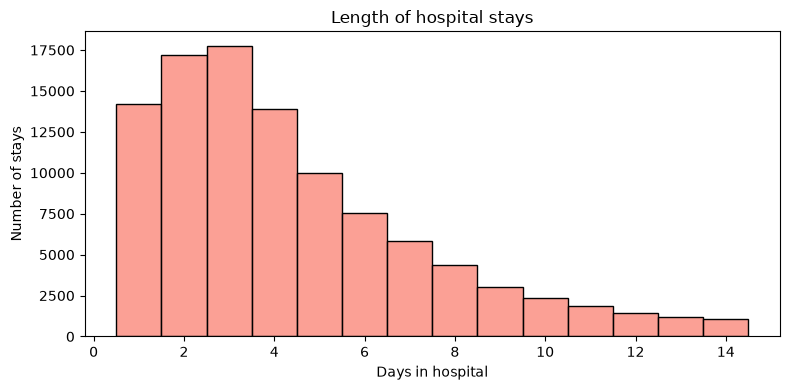

In [23]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="time_in_hospital", discrete=True, color="salmon")
plt.title("Length of hospital stays")
plt.xlabel("Days in hospital")
plt.ylabel("Number of stays")
plt.tight_layout()
plt.show()


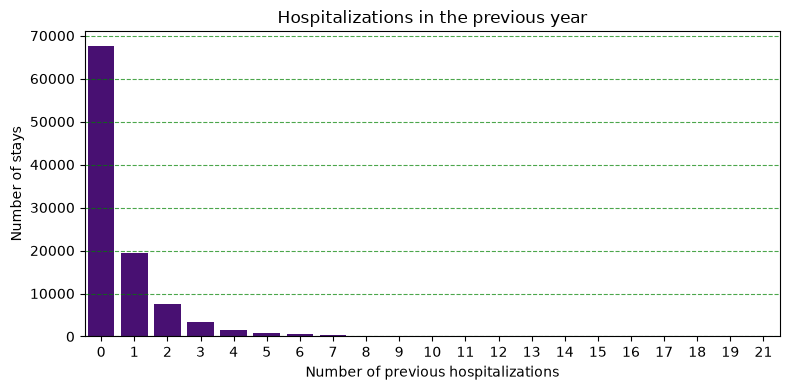

In [24]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="number_inpatient", color="indigo")
plt.grid(axis='y', linestyle='--', alpha=0.7, color='green')
plt.title("Hospitalizations in the previous year")
plt.xlabel("Number of previous hospitalizations")
plt.ylabel("Number of stays")
plt.tight_layout()
plt.show()

##### Now we look into the patients that have been admitted multiple times and patients that have been admitted only once.
##### To break down the maths, we take the number of patients with several stays and subtract it from the unique patients and then add the total stays for patients with several days, which gives us the total number of admissions (101,766).

In [25]:
stays_per_patient = df["patient_nbr"].value_counts()

print("Unique patients:", stays_per_patient.size)
print("Patients with several stays:", (stays_per_patient > 1).sum())
print("Total stays for patients with several stays:", stays_per_patient[stays_per_patient > 1].sum())

Unique patients: 71518
Patients with several stays: 16773
Total stays for patients with several stays: 47021


# 1.6 Splitting the data

##### We split train and test per patient; we import GroupKFold which allows us to split the data whitout separating groups (patient with multiple admissions).
##### We set nsplits = 5 to have an 80/20 split.

In [26]:
from sklearn.model_selection import GroupKFold

split = GroupKFold(n_splits=5, shuffle=True, random_state=42)

train_set, test_set = next(
    split.split(df, y, groups=df["patient_nbr"])
)

X_train = df.iloc[train_set].copy()
X_test = df.iloc[test_set].copy()

y_train = y.iloc[train_set].copy()
y_test = y.iloc[test_set].copy()

##### We verify the sepratation and since the resulet is set(), we know that both sets don't have a common patient.

In [27]:
set(X_train["patient_nbr"]) & set(X_test["patient_nbr"])

set()

##### Next, we store the patient_nbr in groups_train for cross validation then delete them because they aren't medical characteristics.

In [28]:
groups_train = X_train["patient_nbr"]

X_train = X_train.drop(columns=["encounter_id", "patient_nbr"])
X_test = X_test.drop(columns=["encounter_id", "patient_nbr"])

### EDA conclusion

Our goal is to predict whether a hospital stay will be followed by a recorded readmission, regardless of the delay. We plan to make predictions at discharge.

The target is binary: 1 for a recorded readmission (⁠ <30 ⁠ or ⁠ >30 ⁠) and 0 for no recorded readmission (⁠ NO ⁠). About 46% of stays belong to class 1, so the classes are relatively balanced.

The dataset contains 101,766 stays from 71,518 patients. Among these patients, 16,773 have multiple stays. We will therefore split the data by patient to prevent overlap between training and test sets.

Unknown diagnosis codes are represented by an "Unknown" category. Diagnosis codes and other category codes will be treated as categorical variables.

We split the data before fitting any imputation or encoding. Patient and encounter identifiers are excluded from the model's predictors.

# 2. Feature Engineering

##### We do a for loop over each line so we could identify the total number of visits per stay throughout the year before hospitalisation. Then, we devide the number of lab procedures during the encounter by the time spent in hospital to figure out the number of lab procedures per day.

In [29]:
for data in [X_train, X_test]:
    data["previous_visits"] = (
        data["number_outpatient"]
        + data["number_emergency"]
        + data["number_inpatient"]
    )

    data["lab_procedures_per_day"] = (
        data["num_lab_procedures"] / data["time_in_hospital"]
    )

In [30]:
X_train[["previous_visits", "lab_procedures_per_day"]].sample(10)

,previous_visits,lab_procedures_per_day
13442,0,47.000000
90312,9,13.400000
1334,0,12.000000
46862,3,11.000000
80734,0,59.000000
85166,0,0.333333
77948,1,22.000000
39223,0,0.750000
92279,0,28.500000
74623,0,15.333333


##### Separating the numerical and categorical columns.

In [31]:
numeric_columns = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
    "previous_visits",
    "lab_procedures_per_day"
]

categorical_columns = X_train.columns.drop(numeric_columns).tolist()

In [32]:
print("Numerical:", numeric_columns)
print("Categorical:", categorical_columns)

Numerical: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'previous_visits', 'lab_procedures_per_day']
Categorical: ['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'diag_1', 'diag_2', 'diag_3', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide.metformin', 'glipizide.metformin', 'glimepiride.pioglitazone', 'metformin.rosiglitazone', 'metformin.pioglitazone', 'change', 'diabetesMed']


##### We set up the pipelines, where the numerical pipeline we set up the imputer and standard scaler, then for the categorical pipeline we set up the imputer and encoder of choice (OneHotEncoder). We chose OneHotEncoder because we wanted to transform the categories to numbers without creating an order between them and avoid data leakage.

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

##### We add a ColumnTransformer which is a preprocessor which applies the preprocess into the pipeline.

In [34]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# 3. Class Imbalance Handling

##### The training classes are more or less balanced. We should keep the original distribution without oversampling or undersampling.
##### We will compare the models by computing the accuracy, precision, recall, F1-score and ROC-AUC.
##### We will also compare class weighting with no weighting during the model selection and rather during the model training, while also using cross-validation on the development set.

In [35]:
y_train.value_counts(normalize=True) * 100

readmitted
0    53.729185
1    46.270815
Name: proportion, dtype: float64